# ส่วนที่ 0: Import Library

In [63]:
# import the libraries for math and data visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [64]:
# import the libraries for machine learning
from sklearn.tree import DecisionTreeClassifier         
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate  
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score  
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# ส่วนที่ 0: Pull Dataset

In [65]:
# pull data from csv file
data = pd.read_csv('heart.csv')

In [66]:
# show the first 5 rows of the dataset
data.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


# ส่วนที่ 1: Feature Engineering

## 1. Observe the dataset
- ตรวจสอบโครงสร้างและขนาดของชุดข้อมูล
- ตรวจสอบจำนวนระเบียน จำนวนตัวแปร และชนิดข้อมูลของแต่ละตัวแปร
- ตรวจสอบและจัดการข้อมูลที่สูญหาย (Missing Values)

**ตรวจสอบโครงสร้างของ DataFrame** มีจำนวน 918 ชุดข้อมูล

| Feature          | ความหมาย						|
| ---------------- | -------------------------------|
| `Age`            | อายุ                            |
| `Sex`            | เพศ                            |
| `ChestPainType`  | ประเภทอาการเจ็บหน้าอก            |
| `RestingBP`      | ความดันโลหิตขณะพัก              | 
| `Cholesterol`    | คอเลสเตอรอล                    |
| `FastingBS`      | น้ำตาลในเลือดขณะอดอาหาร         |
| `RestingECG`     | ผลคลื่นไฟฟ้าหัวใจขณะพัก           |
| `MaxHR`          | อัตราการเต้นหัวใจสูงสุด           	 |
| `ExerciseAngina` | อาการเจ็บหน้าอกขณะออกกำลังกาย    |
| `Oldpeak`        | ค่าการเปลี่ยนแปลง ST depression  |
| `ST_Slope`       | ความชันของ ST segment          |
| `HeartDisease`   | ผลลัพธ์โรคหัวใจ                  |

In [67]:
# show data information
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


**ตรวจสอบจำนวนแถวและคอลัมน์**
- 918 แถว -> ระเบียน
- 12 คอลัมน์ -> ตัวแปรที่นำมาวิเคราะห์

In [68]:
# show data shape
data.shape

(918, 12)

**ตรวจสอบชนิดข้อมูลของแต่ละตัวแปร**

In [69]:
# show data types
data.dtypes

Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

**ตรวจสอบ Missing Values** ผลคือ ไม่พบค่าว่างในชุดข้อมูลนี้

In [70]:
data.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

## 2. Preprocess numeric data
- ระบุตัวแปรที่เป็นข้อมูลตัวเลข
- เลือกและดำเนินการเตรียมข้อมูลตัวเลขด้วยวิธีที่เหมาะสม

*ตัวแปรตัวเลข* ได้แก่ Age, RestingBP, Cholesterol, FastingBS, MaxHR, Oldpeak, HeartDisease

**ตรวจสอบสถิติของแต่ละตัวแปร**

In [71]:
# show data description statistics
data.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


**ตรวจสอบค่าที่ผิดปกติ (outlier)** โดยการใช้กราฟ Box Plot ในการช่วยพิจารณา

*AI Prompt:* เขียน box plot ของแต่ละตัวแปร Age, RestingBP, Cholesterol, FastingBS, MaxHR, Oldpeak,HeartDisease อยู่ในภาพเดียวกัน

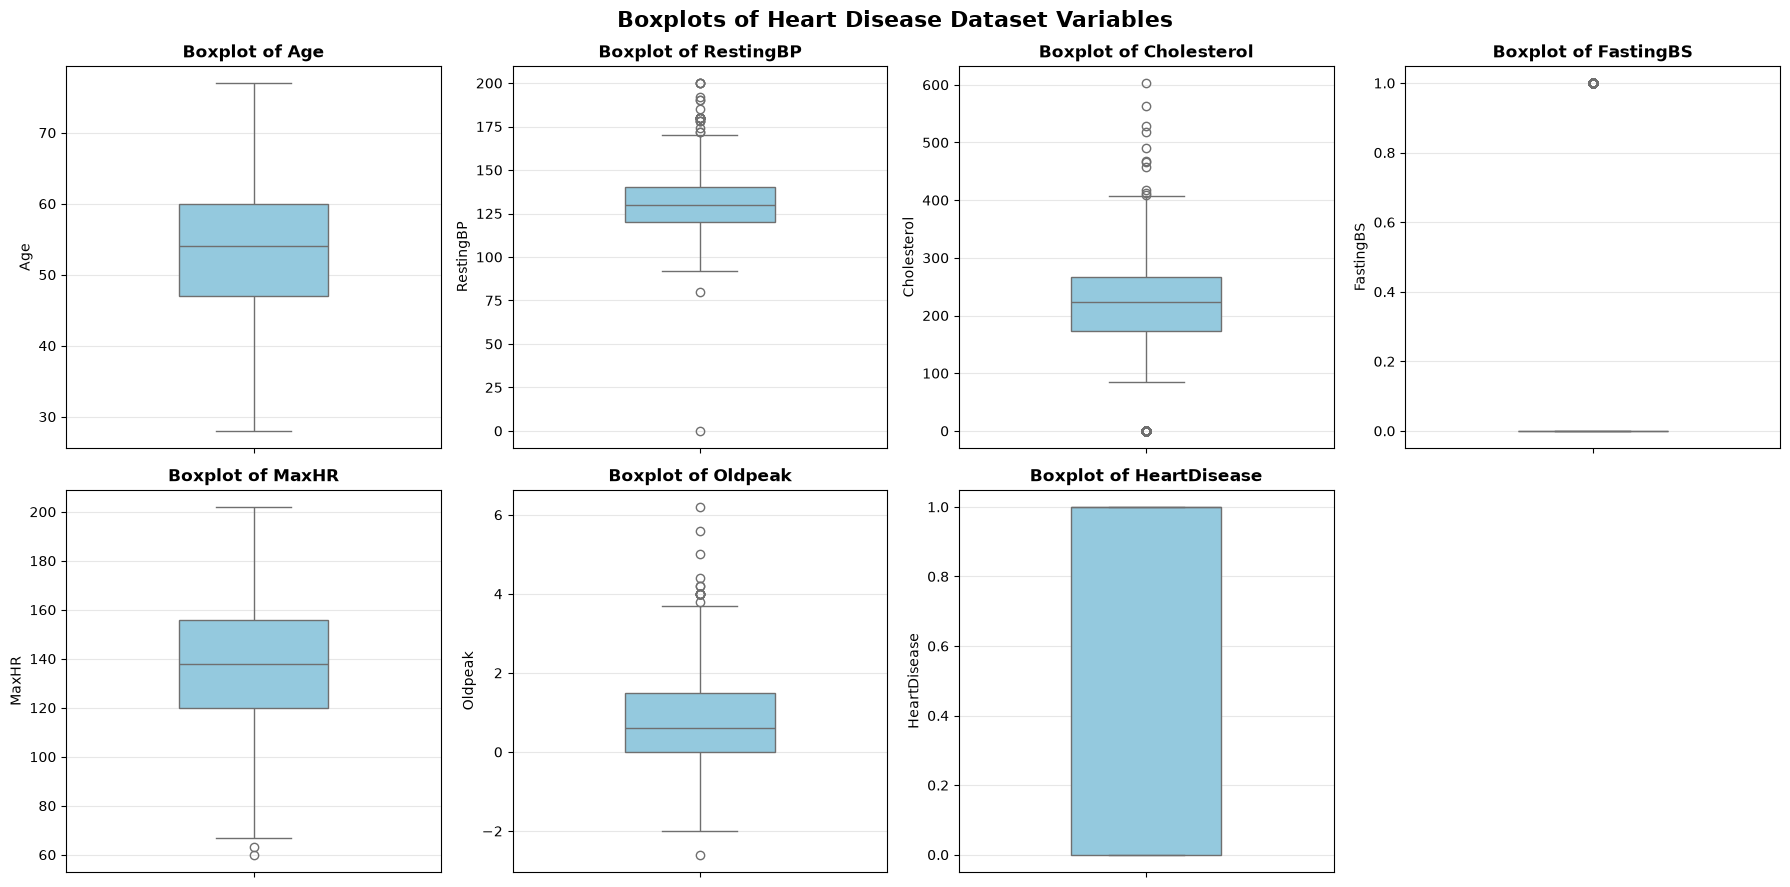

In [72]:
# โหลดข้อมูล
df = pd.read_csv("heart.csv")

# กำหนดตัวแปรที่ต้องการ
numeric_cols = [
    'Age', 'RestingBP', 'Cholesterol',
    'FastingBS', 'MaxHR', 'Oldpeak',
    'HeartDisease'
]

# สร้างกราฟ 2 แถว 4 คอลัมน์
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

# วนลูปสร้าง Boxplot
for i, col in enumerate(numeric_cols):
    sns.boxplot(
        y=df[col],
        ax=axes[i],
        color='skyblue',
        width=0.4
    )

    axes[i].set_title(
        f'Boxplot of {col}',
        fontsize=12,
        fontweight='bold'
    )
    axes[i].set_ylabel(col)
    axes[i].grid(axis='y', alpha=0.3)

# ซ่อนช่องที่ไม่ได้ใช้งาน
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

# ชื่อกราฟหลัก
fig.suptitle(
    'Boxplots of Heart Disease Dataset Variables',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## 3. Preprocess categorical data
- ระบุตัวแปรที่เป็นข้อมูลประเภทหมวดหมู่

- เลือกและดำเนินการแปลงข้อมูลหมวดหมู่ให้อยู่ในรูปแบบตัวเลขด้วยวิธีที่เหมาะสม

*ตัวแปรหมวดหมู่* ได้แก่ Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope

In [73]:
# Convert a object to a categorical data type
data['Sex'] = data['Sex'].astype('category')
data['ChestPainType'] = data['ChestPainType'].astype('category')
data['RestingECG'] = data['RestingECG'].astype('category')
data['ExerciseAngina'] = data['ExerciseAngina'].astype('category')
data['ST_Slope'] = data['ST_Slope'].astype('category')

*AI Prompt:* สามารถเขียนโค้ดเช็คได้ไหมว่า ภายใต้ค่า category ของแต่ละตัวแปร มีค่า/กลุ่มอะไรบ้าง

In [74]:
# Create a summary DataFrame for categorical variables
summary = pd.DataFrame([
    {
        'Variable': col,
        'Data Type': data[col].dtype,
        'Categories Count': data[col].nunique(),
        'Categories': ', '.join(
            data[col].dropna().unique().astype(str)
        ),
        'Missing Values': data[col].isna().sum()
    }
    for col in data.select_dtypes(include=['category']).columns
])

display(summary)

,Variable,Data Type,Categories Count,Categories,Missing Values
0,Sex,category,2,"M, F",0
1,ChestPainType,category,4,"ATA, NAP, ASY, TA",0
2,RestingECG,category,3,"Normal, ST, LVH",0
3,ExerciseAngina,category,2,"N, Y",0
4,ST_Slope,category,3,"Up, Flat, Down",0


In [75]:
mapping_Sex = {
    'M': 0,
    'F': 1
}

data['Sex'] = data['Sex'].map(mapping_Sex)
data.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,0,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,1,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,0,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,1,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,0,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [76]:
mapping_ExerciseAngina = {
    'N': 0,
    'Y': 1
}

data['ExerciseAngina'] = data['ExerciseAngina'].map(mapping_ExerciseAngina)
data.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,0,ATA,140,289,0,Normal,172,0,0.0,Up,0
1,49,1,NAP,160,180,0,Normal,156,0,1.0,Flat,1
2,37,0,ATA,130,283,0,ST,98,0,0.0,Up,0
3,48,1,ASY,138,214,0,Normal,108,1,1.5,Flat,1
4,54,0,NAP,150,195,0,Normal,122,0,0.0,Up,0


In [77]:
# Perform one-hot encoding
data = pd.get_dummies(data, dtype=int, columns=['ChestPainType', 'RestingECG', 'ST_Slope'])
data.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,0,140,289,0,172,0,0.0,0,0,1,0,0,0,1,0,0,0,1
1,49,1,160,180,0,156,0,1.0,1,0,0,1,0,0,1,0,0,1,0
2,37,0,130,283,0,98,0,0.0,0,0,1,0,0,0,0,1,0,0,1
3,48,1,138,214,0,108,1,1.5,1,1,0,0,0,0,1,0,0,1,0
4,54,0,150,195,0,122,0,0.0,0,0,0,1,0,0,1,0,0,0,1


In [78]:
data.dtypes

Age                     int64
Sex                  category
RestingBP               int64
Cholesterol             int64
FastingBS               int64
MaxHR                   int64
ExerciseAngina       category
Oldpeak               float64
HeartDisease            int64
ChestPainType_ASY       int64
ChestPainType_ATA       int64
ChestPainType_NAP       int64
ChestPainType_TA        int64
RestingECG_LVH          int64
RestingECG_Normal       int64
RestingECG_ST           int64
ST_Slope_Down           int64
ST_Slope_Flat           int64
ST_Slope_Up             int64
dtype: object

## 4. Separate all data to Training data and Test data
- แยกตัวแปรอิสระ (Features) ออกจากตัวแปรเป้าหมาย (Target)

- แบ่งข้อมูลเป็นชุดฝึกสอน (Training Set) และชุดทดสอบ (Test Set) ด้วยสัดส่วนที่เหมาะสม

- กำหนด random_state เพื่อให้สามารถทำซ้ำการทดลองได้

In [79]:
# Step 2: Split all data into (1)training data and (2)test data
X = data.iloc[:, 0:4]
y = data.iloc[:, 4]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

# ส่วนที่ 2: Classification Modeling

## 5. Decision Tree
- สร้างและฝึกสอนแบบจำลอง Decision Tree ด้วยชุดข้อมูลฝึกสอน

- ประเมินประสิทธิภาพของแบบจำลองด้วยชุดข้อมูลทดสอบ

In [80]:
"""
from sklearn import tree

# 1. เทรนโมเดลด้วย DecisionTreeClassifier
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

plt.figure(figsize=(30, 20))  
tree.plot_tree(
    clf,
    feature_names=['m_radius', 'm_texture', 'm_perimeter', 'm_area', 'm_smoothness',
                   'm_compactness', 'm_concavity', 'm_concave_points', 'm_symmetry', 
                   'm_fractal_dimension', 'se_radius', 'se_texture', 'se_perimeter', 
                   'se_area', 'se_smoothness', 'se_compactness', 'se_concavity',
                   'se_concave_points', 'se_symmetry', 'se_fractal_dimension', 
                   'w_radius', 'w_texture', 'w_perimeter', 'w_area', 'w_smoothness', 
                   'w_compactness', 'w_concavity', 'w_concave_points', 'w_symmetry', 
                   'w_fractal_dimension'],
    class_names=['B', 'M'],
    filled=True
)
plt.show()
"""

"\nfrom sklearn import tree\n\n# 1. เทรนโมเดลด้วย DecisionTreeClassifier\nclf = DecisionTreeClassifier(max_depth=5, random_state=42)\nclf.fit(X_train, y_train)\n\nplt.figure(figsize=(30, 20))  \ntree.plot_tree(\n    clf,\n    feature_names=['m_radius', 'm_texture', 'm_perimeter', 'm_area', 'm_smoothness',\n                   'm_compactness', 'm_concavity', 'm_concave_points', 'm_symmetry', \n                   'm_fractal_dimension', 'se_radius', 'se_texture', 'se_perimeter', \n                   'se_area', 'se_smoothness', 'se_compactness', 'se_concavity',\n                   'se_concave_points', 'se_symmetry', 'se_fractal_dimension', \n                   'w_radius', 'w_texture', 'w_perimeter', 'w_area', 'w_smoothness', \n                   'w_compactness', 'w_concavity', 'w_concave_points', 'w_symmetry', \n                   'w_fractal_dimension'],\n    class_names=['B', 'M'],\n    filled=True\n)\nplt.show()\n"

In [81]:
"""
#-- Dependent variables
list_accuracy = []
list_precision = []
list_recall = []
list_f1 = []

#-- Independent variables
list_max_depth = []

#-- Selected algorithms
criterion = 'gini'
spliter = 'best'
#criterion = 'entropy'
#spliter = 'random'

for i in range(5, 30, 2):
    clf = tree.DecisionTreeClassifier(criterion=criterion, splitter=spliter ,max_depth=i)
    scoring = ['accuracy', 'precision', 'recall', 'f1']
    scores = cross_validate(clf, X_cross, y_cross, cv=5, scoring=scoring)
    
    list_accuracy.append(np.mean(scores['test_accuracy']))
    list_precision.append(np.mean(scores['test_precision']))
    list_recall.append(np.mean(scores['test_recall']))
    list_f1.append(np.mean(scores['test_f1'])) 
    list_max_depth.append(i)

metrics = ["Accuracy", "Precision", "Recall", "F1"]
data_lists = [list_accuracy, list_precision, list_recall, list_f1]

fig, axes = plt.subplots(1, 4, figsize=(30, 5))
for ax, metric, data in zip(axes, metrics, data_lists):
    ax.plot(list_max_depth, data)
    ax.grid()
    ax.set_title(metric)
    ax.set_xlabel("max_depth")
    ax.set_ylabel(metric)

    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    
"""

'\n#-- Dependent variables\nlist_accuracy = []\nlist_precision = []\nlist_recall = []\nlist_f1 = []\n\n#-- Independent variables\nlist_max_depth = []\n\n#-- Selected algorithms\ncriterion = \'gini\'\nspliter = \'best\'\n#criterion = \'entropy\'\n#spliter = \'random\'\n\nfor i in range(5, 30, 2):\n    clf = tree.DecisionTreeClassifier(criterion=criterion, splitter=spliter ,max_depth=i)\n    scoring = [\'accuracy\', \'precision\', \'recall\', \'f1\']\n    scores = cross_validate(clf, X_cross, y_cross, cv=5, scoring=scoring)\n\n    list_accuracy.append(np.mean(scores[\'test_accuracy\']))\n    list_precision.append(np.mean(scores[\'test_precision\']))\n    list_recall.append(np.mean(scores[\'test_recall\']))\n    list_f1.append(np.mean(scores[\'test_f1\'])) \n    list_max_depth.append(i)\n\nmetrics = ["Accuracy", "Precision", "Recall", "F1"]\ndata_lists = [list_accuracy, list_precision, list_recall, list_f1]\n\nfig, axes = plt.subplots(1, 4, figsize=(30, 5))\nfor ax, metric, data in zip(ax

## 6. Random Forest
- สร้างและฝึกสอนแบบจำลอง Random Forest ด้วยชุดข้อมูลฝึกสอน

- ประเมินประสิทธิภาพของแบบจำลองด้วยชุดข้อมูลทดสอบ

In [82]:
"""
#-- Dependent variables
list_accuracy = []
list_precision = []
list_recall = []
list_f1 = []

#-- Independent variables
list_max_depth = []

#-- Selected algorithms
criterion = 'gini'
#criterion = 'entropy'

for i in range(5, 10):
    clf = RandomForestClassifier(n_estimators=i, criterion=criterion)
    scoring = ['accuracy', 'precision', 'recall', 'f1']
    scores = cross_validate(clf, X_cross, y_cross, cv=5, scoring=scoring)
    
    list_accuracy.append(np.mean(scores['test_accuracy']))
    list_precision.append(np.mean(scores['test_precision']))
    list_recall.append(np.mean(scores['test_recall']))
    list_f1.append(np.mean(scores['test_f1'])) 
    list_max_depth.append(i)

metrics = ["Accuracy", "Precision", "Recall", "F1"]
data_lists = [list_accuracy, list_precision, list_recall, list_f1]

fig, axes = plt.subplots(1, 4, figsize=(30, 5))
for ax, metric, data in zip(axes, metrics, data_lists):
    ax.plot(list_max_depth, data)
    ax.grid()
    ax.set_title(metric)
    ax.set_xlabel("max_depth")
    ax.set_ylabel(metric)

    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    
"""

'\n#-- Dependent variables\nlist_accuracy = []\nlist_precision = []\nlist_recall = []\nlist_f1 = []\n\n#-- Independent variables\nlist_max_depth = []\n\n#-- Selected algorithms\ncriterion = \'gini\'\n#criterion = \'entropy\'\n\nfor i in range(5, 10):\n    clf = RandomForestClassifier(n_estimators=i, criterion=criterion)\n    scoring = [\'accuracy\', \'precision\', \'recall\', \'f1\']\n    scores = cross_validate(clf, X_cross, y_cross, cv=5, scoring=scoring)\n\n    list_accuracy.append(np.mean(scores[\'test_accuracy\']))\n    list_precision.append(np.mean(scores[\'test_precision\']))\n    list_recall.append(np.mean(scores[\'test_recall\']))\n    list_f1.append(np.mean(scores[\'test_f1\'])) \n    list_max_depth.append(i)\n\nmetrics = ["Accuracy", "Precision", "Recall", "F1"]\ndata_lists = [list_accuracy, list_precision, list_recall, list_f1]\n\nfig, axes = plt.subplots(1, 4, figsize=(30, 5))\nfor ax, metric, data in zip(axes, metrics, data_lists):\n    ax.plot(list_max_depth, data)\n    

In [83]:
"""
clf = RandomForestClassifier(n_estimators=15, criterion='gini', max_depth=40)
clf.fit(X_cross, y_cross)
y_pred = clf.predict(X_final)

target_names = ['class 0', 'class 1']
print(classification_report(y_final, y_pred, target_names=target_names, digits=5))

cm = confusion_matrix(y_final, y_pred)
cm_display = ConfusionMatrixDisplay(cm).plot()
"""

"\nclf = RandomForestClassifier(n_estimators=15, criterion='gini', max_depth=40)\nclf.fit(X_cross, y_cross)\ny_pred = clf.predict(X_final)\n\ntarget_names = ['class 0', 'class 1']\nprint(classification_report(y_final, y_pred, target_names=target_names, digits=5))\n\ncm = confusion_matrix(y_final, y_pred)\ncm_display = ConfusionMatrixDisplay(cm).plot()\n"

## 7. Gradient Boost Trees
- สร้างและฝึกสอนแบบจำลอง Gradient Boost Tree ด้วยชุดข้อมูลฝึกสอน

- ประเมินประสิทธิภาพของแบบจำลองด้วยชุดข้อมูลทดสอบ

In [84]:
"""
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

#---------- Load data ----------#
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()

#---------- Parameter tuning ----------#
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.5],
    'max_depth': [3, 5]
}

grid = GridSearchCV(
    estimator=GradientBoostingClassifier(
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Best model
best_gb = grid.best_estimator_

print("Best Parameters")
print(grid.best_params_)

print(f"Best CV F1 Score: {grid.best_score_:.4f}")

#---------- Predict ----------#
y_pred = best_gb.predict(X_test)

# Metrics
print("\n===== Test Result =====")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")

#---------- Confusion Matrix ----------#
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues')
plt.title('Gradient Boosting Confusion Matrix')
plt.show()
"""

'\nfrom sklearn.ensemble import GradientBoostingClassifier\nfrom sklearn.model_selection import GridSearchCV\nfrom sklearn.metrics import (\n    accuracy_score,\n    precision_score,\n    recall_score,\n    f1_score,\n    confusion_matrix,\n    ConfusionMatrixDisplay\n)\n\n#---------- Load data ----------#\nX_train = pd.read_csv(\'X_train.csv\')\nX_test = pd.read_csv(\'X_test.csv\')\n\ny_train = pd.read_csv(\'y_train.csv\').squeeze()\ny_test = pd.read_csv(\'y_test.csv\').squeeze()\n\n#---------- Parameter tuning ----------#\nparam_grid = {\n    \'n_estimators\': [50, 100, 200],\n    \'learning_rate\': [0.01, 0.1, 0.5],\n    \'max_depth\': [3, 5]\n}\n\ngrid = GridSearchCV(\n    estimator=GradientBoostingClassifier(\n        random_state=42\n    ),\n    param_grid=param_grid,\n    cv=5,\n    scoring=\'f1\',\n    n_jobs=-1\n)\n\ngrid.fit(X_train, y_train)\n\n# Best model\nbest_gb = grid.best_estimator_\n\nprint("Best Parameters")\nprint(grid.best_params_)\n\nprint(f"Best CV F1 Score: {gri

## 8. Model Comparison and Selection
- เปรียบเทียบประสิทธิภาพของแบบจำลองทั้ง 3 วิธีด้วยตัวชี้วัดที่เหมาะสม

- เลือกแบบจำลองที่มีประสิทธิภาพดีที่สุด พร้อมอธิบายเหตุผลประกอบการตัดสินใจ